Polynomial Regression and LASSO:
1) Generate artificial data from a second-order polynomial equation with added Gaussian noise.
2) Segregate the data into training and test datasets.
3) Model the data using a tenth-order polynomial with Linear Regression (basis functions approach).
4) Compute the root mean squared error (RMSE) on the test dataset.
5) Now perform regularization using the LASSO model. Vary the regularization coefficient (alpha) and plot the variation of RMSE on the test dataset versus alpha. Take alpha to be positive.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
import matplotlib.pyplot as plt
np.random.seed(42)

In [ ]:
x=np.linspace(0,10,100)
y_real=(1.5*(x**2)-0.5*x-10)
y_noise=np.random.normal(0,10,len(x))
y=y_real+y_noise
x_data=np.transpose([x])
y_data=np.transpose([y])


model=10

x_input=x_data

if(model>1):
  for i in range(model-1):
    power=i+2
    x_input=np.concatenate((x_input,x_data**power),axis=1)

scaler=StandardScaler()


x_scaled=scaler.fit_transform(x_input)

x_train,x_test,y_train,y_test=train_test_split(x_scaled,y_data,test_size=0.2,random_state=2)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.438e+03, tolerance: 2.054e+01
  model = cd_fast.enet_coordinate_descent(


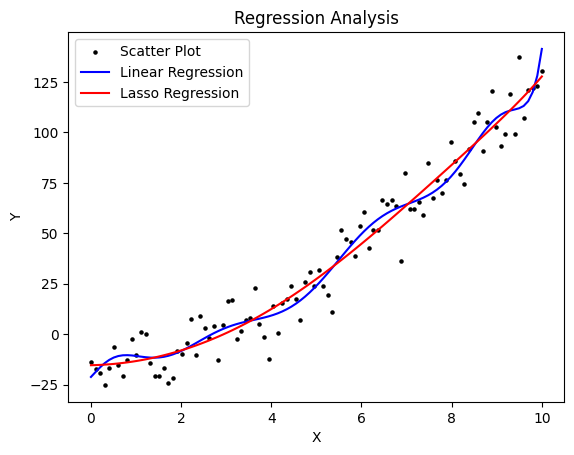

In [ ]:
lin_reg=linear_model.LinearRegression()
lin_reg.fit(x_train,y_train)


y_predict=lin_reg.predict(x_scaled)

lasso_reg=linear_model.Lasso(alpha=0.0001,fit_intercept=True)
lasso_reg.fit(x_scaled,y_data)
y_pred_lasso=lasso_reg.predict(x_scaled)
plt.scatter(x_data,y_data,color='black',s=5)
plt.plot(x_data,y_predict,color='blue',linewidth=1.5)
plt.plot(x_data,y_pred_lasso,color='red',linewidth=1.5)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Regression Analysis")
plt.legend(['Scatter Plot','Linear Regression','Lasso Regression'])
plt.show()

In [ ]:
y_pred=lin_reg.predict(x_test)
rmse_linear=np.sqrt(np.mean(np.square(y_test-y_pred)))
print("Linear Regression Test Data RMSE:",rmse_linear)

y_pred=lasso_reg.predict(x_test)
rmse_lasso=np.sqrt(np.mean(np.square(y_test-y_pred.reshape(-1,1))))
print("Lasso Regression Test Data RMSE:=",rmse_lasso)

Linear Regression Test Data RMSE: 8.795154805572295
Lasso Regression Test Data RMSE:= 7.825682444977774


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.083e+03, tolerance: 1.528e+01
  model = cd_fast.enet_coordinate_descent(


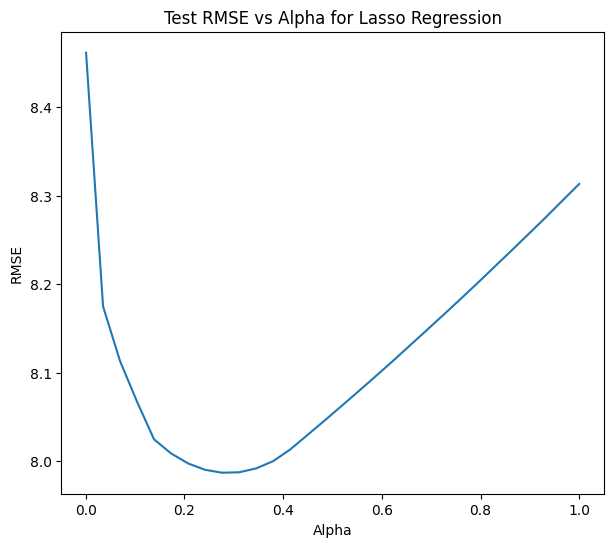

In [ ]:
alphas=np.linspace(0.001,1,30)
rmse_values=[]
for alpha in alphas:
  lasso_reg=linear_model.Lasso(alpha=alpha,fit_intercept=True, max_iter=5000)
  lasso_reg.fit(x_train,y_train)
  y_pred_lasso=lasso_reg.predict(x_test)
  y_pred_lasso=y_pred_lasso.reshape(-1,1)
  rmse=np.sqrt(np.mean(np.square(y_test-y_pred_lasso)))
  rmse_values.append(rmse)

plt.figure(figsize=(7, 6))
plt.plot(alphas,rmse_values, markersize=4)
plt.xlabel("Alpha")
plt.ylabel("RMSE")
plt.title("Test RMSE vs Alpha for Lasso Regression")
plt.show()